#### Exercice 1

##### Etapes 1

In [1]:
import gymnasium as gym

# Create a simple environment perfect for beginners
env = gym.make('CartPole-v1')

# The CartPole environment: balance a pole on a moving cart
# - Simple but not trivial
# - Fast training
# - Clear success/failure criteria

In [2]:
# Run `pip install "gymnasium[classic-control]"` for this example.
import gymnasium as gym

# Create our training environment - a cart with a pole that needs balancing
env = gym.make("CartPole-v1", render_mode="human")

# Reset environment to start a new episode
observation, info = env.reset()
# observation: what the agent can "see" - cart position, velocity, pole angle, etc.
# info: extra debugging information (usually not needed for basic learning)

print(f"Starting observation: {observation}")
# Example output: [ 0.01234567 -0.00987654  0.02345678  0.01456789]
# [cart_position, cart_velocity, pole_angle, pole_angular_velocity]

episode_over = False
total_reward = 0
batch_500_step = 0
limit =  False
want_see_obs = True # True or False

while not episode_over:
    # Choose an action: 0 = push cart left, 1 = push cart right
    action = env.action_space.sample()  # Random action for now - real agents will be smarter!

    # Take the action and see what happens
    observation, reward, terminated, truncated, info = env.step(action)

    # reward: +1 for each step the pole stays upright
    # terminated: True if pole falls too far (agent failed)
    # truncated: True if we hit the time limit (500 steps)

    total_reward += reward

    if (want_see_obs):
        print(f"batch_500_step:{batch_500_step}|reward:{total_reward}|Action space: {env.action_space}|Sample action: {env.action_space.sample()}|Observation space: {env.observation_space}|Sample observation: {env.observation_space.sample()}")  # Discrete(2) - left or right
    

    if (truncated):
        batch_500_step += 1
        print(f"##################################################################################")
        print(f" batch step:{batch_500_step} reward : {total_reward}")
        print(f"##################################################################################")
        print(f"##################################################################################")
        env.reset()

    if (total_reward>100):
        limit = True
    episode_over = limit #terminated or truncated

    

print(f"Episode finished! Total reward: {total_reward}")
env.close()

Starting observation: [ 0.04508641  0.04934926  0.04162656 -0.0080252 ]
batch_500_step:0|reward:1.0|Action space: Discrete(2)|Sample action: 1|Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)|Sample observation: [1.5908583  1.955739   0.39574304 0.2448897 ]
batch_500_step:0|reward:2.0|Action space: Discrete(2)|Sample action: 1|Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)|Sample observation: [-0.8138513   1.5797278  -0.36997792  0.46343625]
batch_500_step:0|reward:3.0|Action space: Discrete(2)|Sample action: 1|Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)|Sample observation: [ 3.3442616 -1.0905612  0.2955225  1.3010337]
batch_500_step:0|reward:4.0|Action space: Discrete(2)|Sample action: 0|Observation space: Box([-4.8      

h:\python_project\projet11\.venv\Lib\site-packages\gymnasium\envs\classic_control\cartpole.py:213: UserWarning: WARN: You are calling 'step()' even though this environment has already returned terminated = True. You should always call 'reset()' once you receive 'terminated = True' -- any further steps are undefined behavior.
  logger.warn(


batch_500_step:0|reward:30.0|Action space: Discrete(2)|Sample action: 1|Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)|Sample observation: [-1.0491563   0.18675575  0.1932032   0.42421427]
batch_500_step:0|reward:30.0|Action space: Discrete(2)|Sample action: 1|Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)|Sample observation: [ 3.1685884  -0.96636516 -0.39516327 -1.5271479 ]
batch_500_step:0|reward:30.0|Action space: Discrete(2)|Sample action: 0|Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)|Sample observation: [ 4.6415133  -0.25833064 -0.17738962 -0.22041903]
batch_500_step:0|reward:30.0|Action space: Discrete(2)|Sample action: 1|Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               i

In [3]:
import gymnasium as gym

# Discrete action space (button presses)
env = gym.make("CartPole-v1")
print(f"Action space: {env.action_space}")  # Discrete(2) - left or right
print(f"Sample action: {env.action_space.sample()}")  # 0 or 1

# Box observation space (continuous values)
print(f"Observation space: {env.observation_space}")  # Box with 4 values
# Box([-4.8, -inf, -0.418, -inf], [4.8, inf, 0.418, inf])
print(f"Sample observation: {env.observation_space.sample()}")  # Random valid observation

Action space: Discrete(2)
Sample action: 0
Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Sample observation: [ 3.8545432   0.6307282  -0.07945774  0.94882804]


In [4]:
import gymnasium as gym
from gymnasium.wrappers import FlattenObservation

# Start with a complex observation space
env = gym.make("CarRacing-v3")
env.observation_space.shape
(96, 96, 3)  # 96x96 RGB image

# Wrap it to flatten the observation into a 1D array
wrapped_env = FlattenObservation(env)
wrapped_env.observation_space.shape
(27648,)  # All pixels in a single array

# This makes it easier to use with some algorithms that expect 1D input

(27648,)

##### Etape 2

In [5]:
# Run `pip install "gymnasium[classic-control]"` for this example.
import gymnasium as gym

# Create our training environment - a cart with a pole that needs balancing
env = gym.make("CartPole-v1", render_mode="human")

# Reset environment to start a new episode
observation, info = env.reset()
# observation: what the agent can "see" - cart position, velocity, pole angle, etc.
# info: extra debugging information (usually not needed for basic learning)

print(f"Starting observation: {observation}")
# Example output: [ 0.01234567 -0.00987654  0.02345678  0.01456789]
# [cart_position, cart_velocity, pole_angle, pole_angular_velocity]

#episode_over = False
#total_reward = 0

for i in range (10) :

    episode_over = False
    total_reward = 0
    steps = []

    while not episode_over:
        # Choose an action: 0 = push cart left, 1 = push cart right
        action = env.action_space.sample()  # Random action for now - real agents will be smarter!

        
        # Take the action and see what happens
        observation, reward, terminated, truncated, info = env.step(action)
        
        steps.append(env.step(action))

        # reward: +1 for each step the pole stays upright
        # terminated: True if pole falls too far (agent failed)
        # truncated: True if we hit the time limit (500 steps)

        total_reward += reward
        episode_over = terminated or truncated

    print(f"Episode {i} finished! Total reward: {total_reward} steps :{steps}")
env.close()

Starting observation: [-0.03030882  0.01512023  0.00114123 -0.02062148]
Episode 0 finished! Total reward: 42.0 steps :[(array([-0.03360678, -0.3751504 ,  0.00617722,  0.565334  ], dtype=float32), 1.0, False, False, {}), (array([-0.05251696, -0.7657141 ,  0.03468303,  1.1580853 ], dtype=float32), 1.0, False, False, {}), (array([-0.07925246, -0.3767709 ,  0.07537426,  0.6025252 ], dtype=float32), 1.0, False, False, {}), (array([-0.09044347,  0.0109963 ,  0.09411483,  0.07061981], dtype=float32), 1.0, False, False, {}), (array([-0.08613051,  0.39828655,  0.09170825, -0.4520345 ], dtype=float32), 1.0, False, False, {}), (array([-0.07412487,  0.0057926 ,  0.08002935,  0.18566509], dtype=float32), 1.0, False, False, {}), (array([-0.07001534,  0.3935116 ,  0.08212791, -0.3458686 ], dtype=float32), 1.0, False, False, {}), (array([-0.05039761,  0.78136975,  0.06297923, -0.87964356], dtype=float32), 1.0, False, False, {}), (array([-0.02306119,  0.38972306,  0.03402946, -0.2612158 ], dtype=float3

---
#### Exercice 2

##### Test

In [6]:
import gymnasium as gym

env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, render_mode="human")

for episode in range(10):
    observation, info = env.reset()

    episode_over = False
    total_reward = 0
    steps = []

    while not episode_over:
        action = env.action_space.sample()

        observation, reward, terminated, truncated, info = env.step(action)

        steps.append((observation, reward, terminated, truncated))
        total_reward += reward

        episode_over = terminated or truncated

    print(f"Episode {episode} | reward = {total_reward} | steps = {len(steps)}")

env.close()

Episode 0 | reward = 0 | steps = 17
Episode 1 | reward = 0 | steps = 79
Episode 2 | reward = 0 | steps = 17
Episode 3 | reward = 0 | steps = 59
Episode 4 | reward = 0 | steps = 32
Episode 5 | reward = 0 | steps = 42
Episode 6 | reward = 0 | steps = 8
Episode 7 | reward = 0 | steps = 16
Episode 8 | reward = 0 | steps = 11
Episode 9 | reward = 0 | steps = 19


##### Etape 1

In [7]:
import numpy as np

# Création de l'environnement
env = gym.make("FrozenLake-v1")

# Récupération du nombre d'états et d'actions
nb_etats = env.observation_space.n
nb_actions = env.action_space.n

# Initialisation de la Q-table
q_table = np.zeros((nb_etats, nb_actions))

# Affichage
print("Dimensions de la Q-table :", q_table.shape)
print(q_table)

Dimensions de la Q-table : (16, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


##### Etape 2

In [ ]:
import gymnasium as gym
import numpy as np
import random

# Création de l'environnement
env = gym.make("FrozenLake-v1", is_slippery=False)

# Initialisation de la Q-table
nb_etats = env.observation_space.n
nb_actions = env.action_space.n
q_table = np.zeros((nb_etats, nb_actions))

# Hyperparamètres
learning_rate = 0.1      # α
discount_factor = 0.99   # γ
epsilon = 1.0            # Taux d'exploration initial
epsilon_decay = 0.999    # Diminution d'epsilon
epsilon_min = 0.01

successes = 0
episodes = 10000
max_steps = 100

# Boucle d'entraînement
for episode in range(episodes):

    state, info = env.reset()

    for step in range(max_steps):

        # Stratégie epsilon-greedy
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()  # Exploration
        else:
            action = np.argmax(q_table[state, :])  # Exploitation

        # Exécution de l'action
        new_state, reward, terminated, truncated, info = env.step(action)

        # Compter les succès
        if reward == 1:
            successes += 1
            # print("But atteint !")

        # Valeur Q maximale du nouvel état
        max_future_q = np.max(q_table[new_state, :])

        # Mise à jour de la Q-table (équation de Bellman)
        q_table[state, action] = q_table[state, action] + learning_rate * (
            reward + discount_factor * max_future_q - q_table[state, action]
        )
        # Nouvelle valeur = Ancienne valeur + taux d′apprentissage × 
        #   (valeur estimée                         − ancienne valeur)

        # Passage à l'état suivant
        state = new_state

        # Fin de l'épisode
        if terminated or truncated:
            break

    # Diminution progressive de l'exploration
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

# Affichage de la Q-table apprise
print("Epsilon final :", epsilon)
print("Nombre de succès :", successes)
print("Q-table finale :")
print(q_table)

Epsilon final : 0.01
Nombre de succès : 8809
Q-table finale :
[[0.94148015 0.93206534 0.95099005 0.94148015]
 [0.94148015 0.         0.96059601 0.95099005]
 [0.95099005 0.970299   0.95098606 0.96059601]
 [0.96059562 0.         0.70952532 0.81799196]
 [0.85548872 0.62552718 0.         0.94148015]
 [0.         0.         0.         0.        ]
 [0.         0.9801     0.         0.960596  ]
 [0.         0.         0.         0.        ]
 [0.38598145 0.         0.89684032 0.42203582]
 [0.56716398 0.75017598 0.98009978 0.        ]
 [0.97029637 0.99       0.         0.97029888]
 [0.         0.         0.         0.        ]
 [0.         0.         0.         0.        ]
 [0.         0.71256858 0.98999971 0.52428248]
 [0.98009515 0.98999972 1.         0.98009949]
 [0.         0.         0.         0.        ]]


Correspondance des états et des cases

| État 0 | État 1 | État 2 | État 3 |
|--------|--------|--------|--------|
| État 4 | État 5 | État 6 | État 7 |
| État 8 | État 9 | État 10 | État 11 |
| État 12 | État 13 | État 14 | État 15 |

Correspondance des actions

| Index | Action |
|------|--------|
| 0 | Gauche |
| 1 | Bas |
| 2 | Droite |
| 3 | Haut |

In [3]:
# Noms des actions
actions = ["Gauche", "Bas", "Droite", "Haut"]

# Récupération de la carte FrozenLake
carte = env.unwrapped.desc

# Affichage de l'en-tête
print(f"{'Etat':<6} {'Case':<8} {'Gauche':>10} {'Bas':>10} {'Droite':>10} {'Haut':>10}")
print("-" * 65)

# Affichage de chaque ligne de la Q-table
for state in range(nb_etats):

    # Coordonnées dans la grille
    ligne = state // 4
    colonne = state % 4

    position = f"({ligne},{colonne})"

    print(
        f"{state:<6} {position:<8} "
        f"{q_table[state,0]:>10.3f} "
        f"{q_table[state,1]:>10.3f} "
        f"{q_table[state,2]:>10.3f} "
        f"{q_table[state,3]:>10.3f}"
    )

Etat   Case         Gauche        Bas     Droite       Haut
-----------------------------------------------------------------
0      (0,0)         0.941      0.932      0.951      0.941
1      (0,1)         0.941      0.000      0.961      0.951
2      (0,2)         0.951      0.970      0.951      0.961
3      (0,3)         0.961      0.000      0.710      0.818
4      (1,0)         0.855      0.626      0.000      0.941
5      (1,1)         0.000      0.000      0.000      0.000
6      (1,2)         0.000      0.980      0.000      0.961
7      (1,3)         0.000      0.000      0.000      0.000
8      (2,0)         0.386      0.000      0.897      0.422
9      (2,1)         0.567      0.750      0.980      0.000
10     (2,2)         0.970      0.990      0.000      0.970
11     (2,3)         0.000      0.000      0.000      0.000
12     (3,0)         0.000      0.000      0.000      0.000
13     (3,1)         0.000      0.713      0.990      0.524
14     (3,2)         0.980      0.

In [11]:
print(gym.__version__)
print(env.spec.id)

1.3.0
FrozenLake-v1


In [12]:
print(env.unwrapped.desc)

[[b'S' b'F' b'F' b'F']
 [b'F' b'H' b'F' b'H']
 [b'F' b'F' b'F' b'H']
 [b'H' b'F' b'F' b'G']]


##### Etape 3

In [2]:
import gymnasium as gym
import numpy as np

# Création de l'environnement
env = gym.make("FrozenLake-v1", is_slippery=False)

# Nombre d'épisodes de test
episodes_test = 100

# Compteur de victoires
total_wins = 0

# Boucle d'évaluation
for episode in range(episodes_test):

    # Réinitialisation de l'environnement
    state, info = env.reset()

    terminated = False
    truncated = False

    while not terminated and not truncated:

        # Toujours choisir la meilleure action connue
        action = np.argmax(q_table[state, :])

        # Exécuter l'action
        new_state, reward, terminated, truncated, info = env.step(action)

        # Passer à l'état suivant
        state = new_state

        # Compter une victoire
        if reward == 1:
            total_wins += 1

# Calcul du taux de réussite
success_rate = (total_wins / episodes_test) * 100

print(f"Taux de réussite sur {episodes_test} épisodes : {success_rate:.0f}%")

Taux de réussite sur 100 épisodes : 100%


---
#### Exercice 3

##### DQN Manuel

In [4]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

Réseau DQN

In [5]:
class DQN(nn.Module):

    def __init__(self, input_size, output_size):
        super(DQN, self).__init__()

        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, output_size)


    def forward(self, x):

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x

Replay Buffer

In [6]:
class ReplayBuffer:

    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)


    def push(self, state, action, reward, next_state, done):

        self.buffer.append(
            (state, action, reward, next_state, done)
        )


    def sample(self, batch_size):

        return random.sample(
            self.buffer,
            batch_size
        )


    def __len__(self):

        return len(self.buffer)

Environnement

In [7]:
env = gym.make("CartPole-v1")


state_size = env.observation_space.shape[0]
action_size = env.action_space.n

Hyperparamètres

In [ ]:
# Hyperparamètres
episodes = 500
gamma = 0.99
learning_rate = 0.001
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995
batch_size = 64
memory_size = 10000
target_update = 10


# Réseaux
policy_net = DQN(state_size, action_size)
target_net = DQN(state_size, action_size)

target_net.load_state_dict(policy_net.state_dict())

# Mémoire
memory = ReplayBuffer(memory_size)

Réseaux

In [15]:
policy_net = DQN(state_size, action_size)

target_net = DQN(state_size, action_size)


# Le target network commence identique
target_net.load_state_dict(policy_net.state_dict())

# Pas d'entraînement sur target_net
target_net.eval()


optimizer = optim.Adam(
    policy_net.parameters(),
    lr=learning_rate
)


memory = ReplayBuffer(memory_size)

Fonction d'optimisation

In [16]:

def optimize_model():

    if len(memory) < batch_size:
        return


    # Récupération d'un batch
    transitions = memory.sample(batch_size)


    states, actions, rewards, next_states, dones = zip(*transitions)


    states = torch.FloatTensor(np.array(states))

    actions = torch.LongTensor(actions).unsqueeze(1)

    rewards = torch.FloatTensor(rewards)

    next_states = torch.FloatTensor(np.array(next_states))

    dones = torch.FloatTensor(dones)



    # --------------------------
    # Q-values actuelles
    # --------------------------

    current_q_values = policy_net(states)


    # On garde uniquement les actions jouées
    current_q_values = current_q_values.gather(
        1,
        actions
    ).squeeze(1)



    # --------------------------
    # Q-values futures
    # calculées avec target_net
    # --------------------------

    with torch.no_grad():

        next_q_values = target_net(next_states).max(1)[0]


        target_q_values = rewards + (
            gamma * next_q_values * (1 - dones)
        )



    # --------------------------
    # Calcul de la loss
    # --------------------------

    loss = F.smooth_l1_loss(
        current_q_values,
        target_q_values
    )


    # --------------------------
    # Mise à jour du réseau
    # --------------------------

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

In [17]:
# ==========================
# Boucle d'entraînement
# ==========================

rewards_history = []


for episode in range(episodes):


    state, info = env.reset()

    total_reward = 0


    done = False


    while not done:


        # ----------------------
        # Choix de l'action
        # ----------------------

        if random.random() < epsilon:

            action = env.action_space.sample()

        else:

            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            action = policy_net(state_tensor).argmax().item()



        # ----------------------
        # Action dans l'environnement
        # ----------------------

        next_state, reward, terminated, truncated, info = env.step(action)


        done = terminated or truncated



        # Stockage expérience

        memory.push(
            state,
            action,
            reward,
            next_state,
            done
        )


        state = next_state

        total_reward += reward



        # Apprentissage

        optimize_model()



    # diminution epsilon

    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )


    rewards_history.append(total_reward)



    # Mise à jour target network

    if episode % target_update == 0:

        target_net.load_state_dict(
            policy_net.state_dict()
        )



    if episode % 50 == 0:

        print(
            f"Episode {episode}, récompense : {total_reward}, epsilon : {epsilon:.3f}"
        )

Episode 0, récompense : 35.0, epsilon : 0.995
Episode 50, récompense : 34.0, epsilon : 0.774
Episode 100, récompense : 25.0, epsilon : 0.603
Episode 150, récompense : 17.0, epsilon : 0.469
Episode 200, récompense : 95.0, epsilon : 0.365
Episode 250, récompense : 200.0, epsilon : 0.284
Episode 300, récompense : 13.0, epsilon : 0.221
Episode 350, récompense : 53.0, epsilon : 0.172
Episode 400, récompense : 56.0, epsilon : 0.134
Episode 450, récompense : 500.0, epsilon : 0.104


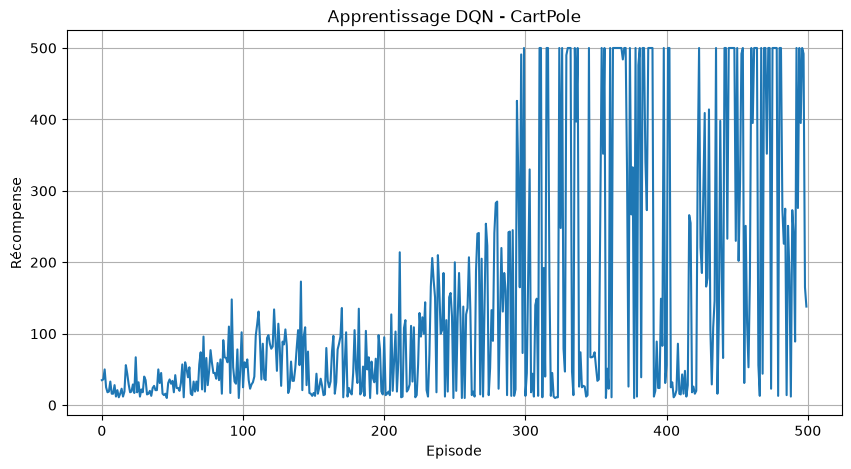

In [18]:
# ==========================
# Graphique
# ==========================

plt.figure(figsize=(10,5))

plt.plot(rewards_history)

plt.xlabel("Episode")

plt.ylabel("Récompense")

plt.title("Apprentissage DQN - CartPole")

plt.grid()

plt.show()

##### SB3

In [1]:
import torch
from torch.utils.tensorboard import SummaryWriter

print("TensorBoard PyTorch OK")


import stable_baselines3.common.logger as logger

print(logger.SummaryWriter)

TensorBoard PyTorch OK
<class 'torch.utils.tensorboard.writer.SummaryWriter'>


In [2]:
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy
import tensorboard

In [3]:
env = gym.make("CartPole-v1")

model = DQN(
    "MlpPolicy",
    env,
    verbose=1,
    tensorboard_log="./logs/"
)

model.learn(
    total_timesteps=25000
)

mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100
)

print(
    f"Récompense moyenne : {mean_reward:.2f} +/- {std_reward:.2f}"
)

model.save("dqn_cartpole")



Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./logs/DQN_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 26.5     |
|    ep_rew_mean      | 26.5     |
|    exploration_rate | 0.96     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1201     |
|    time_elapsed     | 0        |
|    total_timesteps  | 106      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.543    |
|    n_updates        | 1        |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 24.8     |
|    ep_rew_mean      | 24.8     |
|    exploration_rate | 0.925    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1274     |
|    time_elapsed     | 0        |
|    total_timesteps  | 198      |
| train

h:\python_project\projet11\.venv\Lib\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Récompense moyenne : 30.77 +/- 7.39


In [30]:
import sys
import stable_baselines3.common.logger as logger

print(logger.SummaryWriter)
print(sys.executable)
print(tensorboard.__version__)


None
h:\python_project\projet11\.venv\Scripts\python.exe
2.21.0


In [31]:
import torch

print(torch.__version__)

from torch.utils.tensorboard import SummaryWriter

print("PyTorch TensorBoard OK")

2.12.1+cpu
PyTorch TensorBoard OK


In [4]:
model = DQN(
    "MlpPolicy",
    env,
    learning_rate=0.001,
    buffer_size=10000,
    batch_size=64,
    gamma=0.99,
    learning_starts=64,
    exploration_initial_eps=1.0,
    exploration_final_eps=0.01,
    exploration_fraction=0.5,
    verbose=1
)

model.learn(total_timesteps=250000)

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 19       |
|    ep_rew_mean      | 19       |
|    exploration_rate | 0.999    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 4749     |
|    time_elapsed     | 0        |
|    total_timesteps  | 76       |
| train/              |          |
|    learning_rate    | 0.001    |
|    loss             | 0.587    |
|    n_updates        | 2        |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 24       |
|    ep_rew_mean      | 24       |
|    exploration_rate | 0.998    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1651     |
|    time_elapsed     | 0        |
|    total_timesteps  | 192      |
| train/              |        

In [5]:
mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100
)

print(
    f"Récompense moyenne : {mean_reward:.2f} +/- {std_reward:.2f}"
)

Récompense moyenne : 89.97 +/- 2.57


### Mission

In [14]:
import gymnasium as gym

env = gym.make("LunarLander-v3", render_mode="human")

obs, info = env.reset()

done = False
total_reward = 0

while not done:
    action = env.action_space.sample()  # action aléatoire
    obs, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    done = terminated or truncated

env.close()

print("Score total :", total_reward)

Score total : -336.03513583588915
